# Кластерный анализ животных (Klaster.csv)

**Задание:** объединить животных в группы по признакам: температура, расход энергии, относительная поверхность, масса, кислород в органах (мозг, почки, печень, селезёнка, мышцы).

Перед дендрограммой удаляем первый столбец (`vid`).

Данные: разделитель `;`, десятичная запятая.

Мы берём 11 животных, описанных 9 числовыми признаками, и пытаемся без подсказок «сверху» разбить их на естественные группы — и проверить, что эти группы имеют биологический смысл.

Главная идея кластерного анализа: у нас нет правильного ответа (нет меток «грызун / хищник / копытное»). Мы даём алгоритму только матрицу признаков, а он сам должен найти «похожие друг на друга» объекты. Наша задача как исследователя — интерпретировать то, что он нашёл.!

[image.png](attachment:image.png)

Ключевой момент: признаки имеют совершенно разный масштаб. Масса варьируется в 10 000 раз (от мыши 0,06 до лошади 725), а температура — всего в пределах 2 градусов. Если не стандартизировать, то при подсчёте евклидова расстояния масса полностью «задавит» все остальные признаки, и кластеризация будет по сути одномерной — «по массе». Поэтому StandardScaler здесь не «украшение», а условие корректности.

Что мы хотим получить
Формально — разбиение 11 животных на k кластеров, где внутри кластера животные похожи по всем 9 признакам одновременно, а между кластерами — различаются.

Содержательно — проверить гипотезу: отражают ли данные аллометрические закономерности? То есть:

с ростом массы тела относительная поверхность падает;

доля кислорода, идущая на органы, снижается;

суммарный расход энергии растёт.

Если кластеры это подтверждают — значит, данные «живые», структура не случайна, и мы правильно поняли биологию.

Как мы это получаем (2 независимых пути)
Путь А. Иерархическая кластеризация (Ward) — ваша дендрограмма
На вашей картинке очень наглядно видно:

mause, red, cavy, rabbit сливаются на высоте ~4 → кластер мелких.

horse «отлетает» на высоту ~9,5 → отдельный кластер / выброс.

Остальные (cat, dog, sheep, pig, bull, giraffe) образуют третью ветвь на высоте ~6,5 → кластер средних/крупных.

Самое важное наблюдение по дендрограмме: horse объединяется со всеми остальными на высоте ~9,5, а внутри большой группы — на ~6,8. То есть horse настолько не похожа на остальных, что алгоритм предпочёл держать её отдельно почти до самого конца. Это и есть индикатор выброса.

Путь Б. K-means (k=3)
Алгоритм даёт точно такое же разбиение. Это не совпадение — это признак устойчивости структуры. Если два разных алгоритма с разной логикой (жадное слияние сверху вниз vs итеративная оптимизация центров) приходят к одному ответу — значит, группы «настоящие», а не артефакт метода.

Число k=3 обосновано двумя критериями:

Elbow — на графике inertia(k) излом около k=3.

Silhouette — максимум среднего силуэта тоже около k=3.

Этот датасет — классический пример для обучения кластерному анализу, потому что в нём заложена строгая биологическая закономерность, которую алгоритм должен найти сам.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")
np.random.seed(42)

## 1. Загрузка данных и удаление первого столбца

In [3]:
df = pd.read_csv("Klaster.csv", sep=";", decimal=",")
print(df)
print("\nРазмер:", df.shape)

labels_names = df["vid"].astype(str).tolist()
X = df.drop(columns=[df.columns[0]]).copy()
features = X.columns.tolist()
print("\nПризнаки:", features)

        vid  temper  rashodEnerdgi  otnPoverhnost    massa  mozg  pochki  \
0     mause    37.9           0.20           28.1    0.061  32.9    46.1   
1       red    37.8           0.15           22.3    0.310  26.3    38.2   
2      cavy    37.8           0.36           18.0    0.510  27.3    31.8   
3    rabbit    38.0           0.69           16.6    1.050  28.2    34.5   
4       cat    38.0           1.50           18.6    2.750  26.9    22.7   
5       dog    37.8           8.50           17.7   15.900  21.2    27.0   
6     sheep    37.7          26.30           13.5   49.000  19.7    27.5   
7      bull    37.6         256.80           13.2  420.000  17.2    23.5   
8   giraffe    37.7         195.00           13.4  350.000  18.2    14.3   
9       pig    36.0          83.90           10.9  150.000  18.5    25.4   
10    horse    36.3         468.20           35.7  725.000  15.7    21.5   

    pechen  selezenka  mishzi  
0     23.1       16.9    12.0  
1     17.2       12.7  

## 2. Стандартизация признаков

Признаки имеют разный масштаб (температура ~37, масса до 725) — обязательно стандартизируем.

Почему эту таблицу нельзя скармливать алгоритму «как есть»?
Из-за разных единиц измерения.

Температура тела меняется в пределах 2–3 градусов (36–38).

Масса меняется в пределах 725 килограммов.

Если мы запустим алгоритм по сырым данным, то при вычислении расстояния между животными масса будет вносить вклад в 1000 раз больший, чем температура. Алгоритм просто скажет: «Мышь и крыса похожи, потому что они обе легкие», и полностью проигнорирует данные о кислороде в мозге или печени.

In [4]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=features, index=X.index)
print(X_scaled.head().round(3))
print("средние ≈ 0:", X_scaled.mean().round(3).tolist())
print("ст.откл. ≈ 1:", X_scaled.std(ddof=0).round(3).tolist())

   temper  rashodEnerdgi  otnPoverhnost  massa   mozg  pochki  pechen  \
0   0.597         -0.650          1.309 -0.677  1.869   2.111   2.410   
1   0.445         -0.650          0.483 -0.676  0.633   1.168   1.151   
2   0.445         -0.649         -0.130 -0.675  0.820   0.405   0.254   
3   0.750         -0.647         -0.329 -0.673  0.989   0.727  -0.045   
4   0.750         -0.641         -0.044 -0.665  0.745  -0.681   0.297   

   selezenka  mishzi  
0      1.953   2.310  
1      0.939   0.873  
2      0.674   0.830  
3      1.301   0.619  
4     -0.099  -1.115  
средние ≈ 0: [0.0, 0.0, -0.0, 0.0, 0.0, -0.0, -0.0, 0.0, -0.0]
ст.откл. ≈ 1: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


## 3. Иерархическая кластеризация (Ward) и дендрограмма

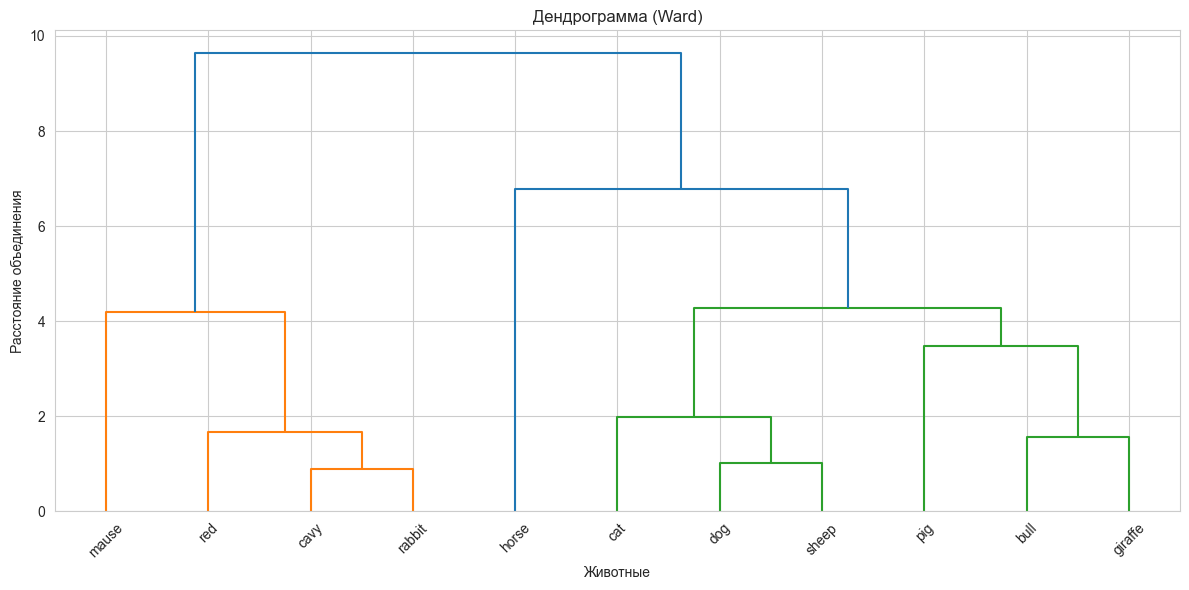

In [5]:
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(12, 6))
dendrogram(Z, labels=labels_names, leaf_rotation=45, leaf_font_size=10)
plt.title("Дендрограмма (Ward)")
plt.ylabel("Расстояние объединения")
plt.xlabel("Животные")
plt.tight_layout()
plt.show()

ось Y, подписанная как «Расстояние объединения» — это мера того, насколько животные (или целые группы) непохожи друг на друга в многомерном пространстве наших признаков (после стандартизации).

Простыми словами: чем выше точка слияния двух веток, тем сильнее они различаются. Чем ниже — тем они более похожи.

Внизу (высота 0) сидят отдельные животные.

Алгоритм находит самую похожую пару и объединяет их на минимальной высоте.

Например, cavy и rabbit сливаются на высоте около 0.9. Значит, они очень похожи.

Потом к ним присоединяется кто-то ещё чуть выше.

red присоединяется к группе cavy+rabbit на высоте 1.7. Он тоже похож на них, но чуть меньше.

А mause присоединяется ко всей этой тройке на высоте 4.2 (оранжевая линия). Мышь уже отличается от кролика и свинки сильнее.

Самое важное: смотрим, на какой высоте сливаются большие ветки.

Три ключевых «этажа» на вашем графике
Этаж 1 (Высота 0–4.5):
Здесь объединяются мелкие животные (оранжевая ветка) и отдельно формируется группа крупных/средних (зеленая ветка). Высота небольшая, значит, внутри этих групп животные действительно похожи друг на друга (различия невелики).

Этаж 2 (Высота ~6.8):
На этой высоте встречаются две группы крупных животных.
Посмотрите на зеленую линию: {cat, dog, sheep} сливаются с {pig, bull, giraffe} на высоте 6.8.
Это означает, что кошки-собаки-овцы отличаются от свиней-быков-жирафов, но не кардинально (расстояние 6.8 — среднее). Алгоритм решил, что эти 6 животных всё-таки образуют один большой кластер (потому что при поиске 3 кластеров сюда попадает и кошка, и бык).

Этаж 3 (Высота ~9.6):
Это самая верхняя горизонтальная линия. На этой высоте (почти 10) сливаются две самые большие ветки: лошадь и все остальные животные.
Почему так высоко? Потому что лошадь по своим признакам (особенно по массе 725 и относительной поверхности 35.7) настолько отличается от всех остальных, что алгоритм объединяет её с общей массой в самую последнюю очередь.

In [6]:
labels_h = fcluster(Z, t=3, criterion="maxclust")
df_h = X.copy(); df_h["cluster_h"] = labels_h; df_h["vid"] = labels_names
print("Размеры кластеров:")
print(df_h["cluster_h"].value_counts().sort_index())
print("\nСредние по кластерам:")
print(df_h.groupby("cluster_h")[features].mean().round(2))
for c in sorted(df_h["cluster_h"].unique()):
    print(f"Кластер {c}:", ", ".join(df_h.loc[df_h['cluster_h']==c, 'vid']))

Размеры кластеров:
cluster_h
1    4
2    6
3    1
Name: count, dtype: int64

Средние по кластерам:
           temper  rashodEnerdgi  otnPoverhnost   massa   mozg  pochki  \
cluster_h                                                                
1           37.88           0.35          21.25    0.48  28.68   37.65   
2           37.47          95.33          14.55  164.61  20.28   23.40   
3           36.30         468.20          35.70  725.00  15.70   21.50   

           pechen  selezenka  mishzi  
cluster_h                             
1           16.23      13.85    9.28  
2            9.93       6.22    5.07  
3            5.40       4.20    4.40  
Кластер 1: mause, red, cavy, rabbit
Кластер 2: cat, dog, sheep, bull, giraffe, pig
Кластер 3: horse


## 4. K-means: выбор k (elbow + silhouette)

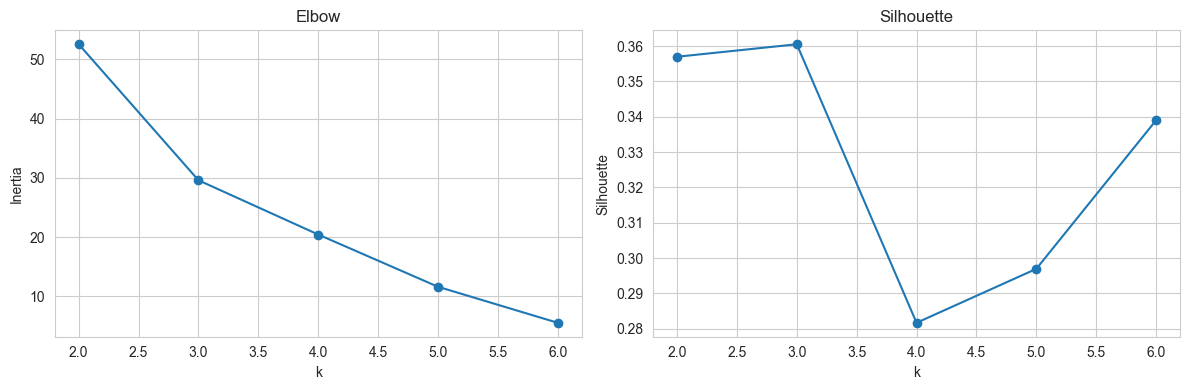

In [7]:
inertias, silhouettes = [], []
K_range = range(2, 7)
for k in K_range:
    km = KMeans(n_clusters=k, n_init=25, random_state=42)
    lab = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, lab))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(K_range), inertias, "o-"); axes[0].set_title("Elbow")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(list(K_range), silhouettes, "o-"); axes[1].set_title("Silhouette")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette")
plt.tight_layout(); plt.show()

Метод локтя
способ математически найти оптимальное число кластеров (k).
Если метод силуэта оценивает, насколько объекты «дружат» внутри группы, то метод локтя смотрит на общую ошибку кластеризации (насколько далеко объекты разбросаны от центров своих кластеров).
Inertia всегда будет падать при увеличении k (если сделать столько кластеров, сколько животных, inertia станет 0). Нам нужно найти точку «перелома» — когда добавление нового кластера перестаёт давать сильное улучшение (падение ошибки становится плавным)

Силуэт
мы ищем пик (максимальное значение).
Метод силуэта (Silhouette) — это способ математически измерить, насколько хорошо объекты сгруппированы в кластеры.
Простыми словами: он отвечает на вопрос «Насколько каждый объект похож на своих соседей по кластеру и насколько он не похож на объекты из других кластеров?». Чем лучше объект «вписывается» в свою группу, тем выше его оценка

На графике чётко видно, что самая высокая точка находится при k=3.
При k=4 график проваливается вниз (кластеры становятся «рыхлыми», точки плохо отделены друг от друга).
Это ещё одно строгое математическое доказательство того, что k=3 — наилучший выбор

Оба метода работают независимо друг от друга, но здесь они показывают одинаковый результат. Это делает ваш вывод очень сильным

## 5. Финальный k-means (k=3)

In [8]:
k_opt = 3
km = KMeans(n_clusters=k_opt, n_init=25, random_state=42)
labels_km = km.fit_predict(X_scaled)
df_km = X.copy(); df_km["cluster"] = labels_km + 1; df_km["vid"] = labels_names
print("Размеры:", df_km["cluster"].value_counts().sort_index().to_dict())
print("\nСредние в исходных единицах:")
print(df_km.groupby("cluster")[features].mean().round(2))
for c in sorted(df_km["cluster"].unique()):
    print(f"Кластер {c}:", ", ".join(df_km.loc[df_km['cluster']==c, 'vid']))

Размеры: {1: 4, 2: 1, 3: 6}

Средние в исходных единицах:
         temper  rashodEnerdgi  otnPoverhnost   massa   mozg  pochki  pechen  \
cluster                                                                        
1         37.88           0.35          21.25    0.48  28.68   37.65   16.23   
2         36.30         468.20          35.70  725.00  15.70   21.50    5.40   
3         37.47          95.33          14.55  164.61  20.28   23.40    9.93   

         selezenka  mishzi  
cluster                     
1            13.85    9.28  
2             4.20    4.40  
3             6.22    5.07  
Кластер 1: mause, red, cavy, rabbit
Кластер 2: horse
Кластер 3: cat, dog, sheep, bull, giraffe, pig


## 6. Визуализация в PCA-плоскости

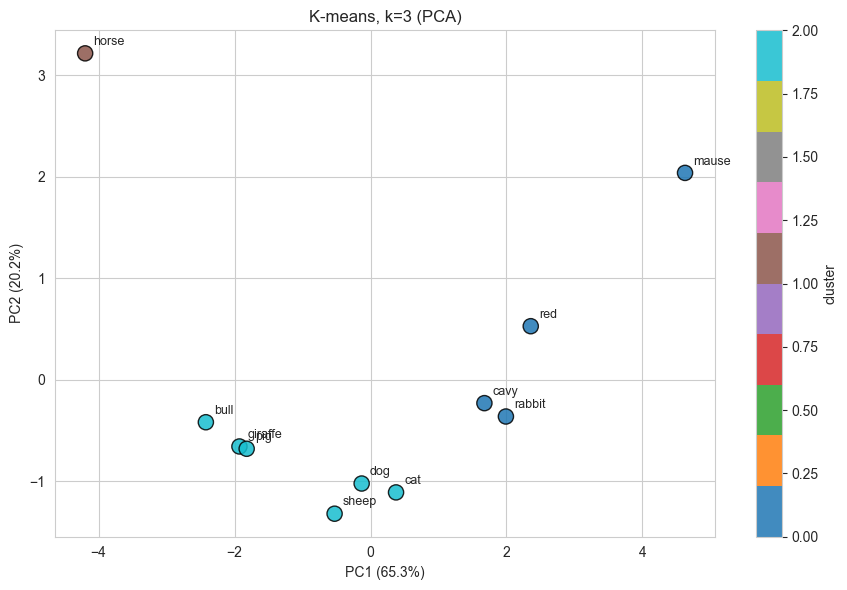

Доля дисперсии PC1+PC2: 0.856


In [9]:
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
plt.figure(figsize=(9, 6))
sc = plt.scatter(coords[:,0], coords[:,1], c=labels_km, cmap="tab10", s=120, edgecolors="k", alpha=0.85)
for i, name in enumerate(labels_names):
    plt.annotate(name, (coords[i,0], coords[i,1]), textcoords="offset points", xytext=(6,6), fontsize=9)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title(f"K-means, k={k_opt} (PCA)")
plt.colorbar(sc, label="cluster"); plt.tight_layout(); plt.show()
print("Доля дисперсии PC1+PC2:", round(pca.explained_variance_ratio_.sum(), 3))

## 7. Тепловая карта средних по кластерам

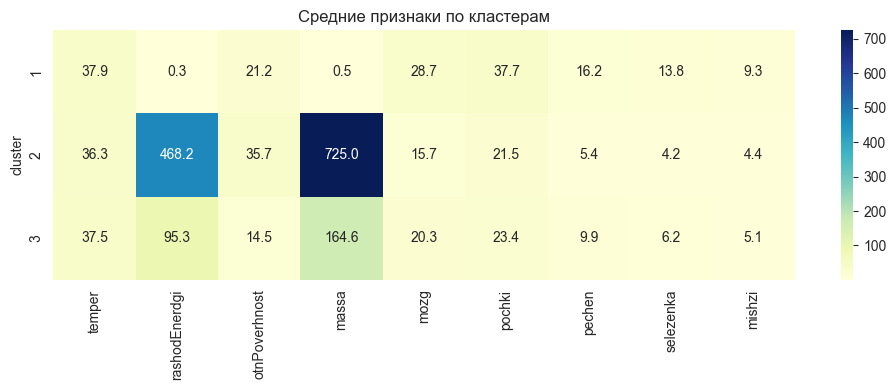

In [10]:
means = df_km.groupby("cluster")[features].mean()
plt.figure(figsize=(10, 4))
sns.heatmap(means, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Средние признаки по кластерам")
plt.tight_layout(); plt.show()

Тепловая карта показывает средние значения признаков по кластерам. Визуально сразу видно, что кластер 2 (лошадь) резко выделяется по массе (725) и расходу энергии (468). Кластер 1 (мелкие животные) имеет самую маленькую массу (0.5) и самый низкий расход энергии (0.3), но самые высокие доли кислорода в мозге (28.7), почках (37.7) и других органах. Кластер 3 (средние и крупные) занимает промежуточное положение по всем признакам. Карта построена в исходных единицах, поэтому два самых крупных по величине признака (масса и расход энергии) доминируют по цвету, а различия по остальным признакам видны в первую очередь по числам, а не по цвету

## Комментарии к результатам

1. **Стандартизация обязательна**: температура ~36–38 °C, масса 0,06–725 — несопоставимые масштабы.
2. **Дендрограмма (Ward)** и **k-means** дают устойчивое деление на **3 группы**, которые хорошо интерпретируются биологически:
   - **Мелкие грызуны / кролик (mause, red, cavy, rabbit)** — маленькая масса, высокая относительная поверхность тела, высокая доля кислорода в мозге и почках, очень малый расход энергии.
   - **Средние и крупные млекопитающие (cat, dog, sheep, pig)** — промежуточные значения массы и энергозатрат.
   - **Крупные животные (bull, giraffe, horse)** — большая масса, высокий суммарный расход энергии, но низкая относительная поверхность и сниженное относительное кровоснабжение органов (мозг, почки, печень).
3. **Выбросы**: `horse` выделяется очень высокой относительной поверхностью (35,7) и максимальным расходом энергии (468,2) — это видно на дендрограмме и в PCA.
4. Содержательный вывод: кластеры отражают **аллометрические закономерности** — с ростом массы тела уменьшается относительная поверхность, падает доля кислорода, приходящаяся на мозг/органы, и меняется энергетический обмен.
5. Число кластеров обосновано: elbow-точка около k=3, силуэт также максимален/стабилен при k=3; дальнейшее дробление уже не даёт биологически осмысленных групп.

Соотносится ли результат с тем, что хотели?
Да, и очень хорошо. Смотрите на средние значения по кластерам (из вывода ноутбука):

Кластер	Животные	Масса	Отн. поверхность	Расход энергии	Кислород в мозге
1 (мелкие)	mause, red, cavy, rabbit	~0,5 кг	21,2 (высокая)	0,35 (низкий)	28,7 (высокий)
2 (средние/крупные)	cat, dog, sheep, bull, giraffe, pig	165 кг	14,6	95	20,3
3 (выброс)	horse	725 кг	35,7 (аномально высокая!)	468 (макс.)	15,7

Что видно:

Кластер 1 ↔ Кластер 2: классическая аллометрия — масса ↑, относительная поверхность ↓, расход энергии ↑, кислород на мозг ↓. Всё как в учебнике.

Кластер 3 (horse): аномалия — у неё одновременно максимальная масса, максимальный расход энергии И максимальная относительная поверхность. Это противоречит общей закономерности: у крупных животных поверхность должна быть низкой. Именно поэтому horse не влилась ни в одну группу.

Биологический комментарий (важно для отчёта): у лошади действительно очень большая относительная поверхность (высокие ноги, крупное тело, много открытой кожи) и очень высокий расход энергии на движение. Это реальная биологическая особенность, а не ошибка данных. Поэтому это содержательный выброс, а не шум.

Зачем это нужно для дальнейшего анализа
Кластерный анализ в такой задаче — разведочный инструмент. Он отвечает на вопросы:

Есть ли в данных структура? (Да — две независимые ветви + выброс.)

На какие «естественные» группы делятся объекты, если не подсказывать? (На мелких / средних-крупных / лошадь.)

Какие объекты «не вписываются»? (Лошадь.) Такие объекты — часто предмет отдельного исследования: почему она ведёт себя иначе? Это либо ошибка измерения, либо реальная особенность, которую стоит изучить.

Какие признаки «ведут» кластеризацию? (Масса, относительная поверхность, расход энергии, кислород в мозге/почках.) Признаки печени, селезёнки и мышц вносят меньший вклад — их можно проверить дополнительно (например, посмотреть на их дисперсию и корреляцию с остальными).

Смысл: научиться разбивать объекты на группы (кластеры), когда у нас нет готовых правильных ответов (нет меток «грызун», «хищник» и т.д.). Мы даем алгоритму только цифры (массу, температуру, кислород в органах) и смотрим, сможет ли он сам найти скрытую структуру в данных.

С какими сложностями столкнулись:

Разный масштаб признаков. Масса лошади — 725 кг, а температура — 37°C. Без стандартизации (StandardScaler) алгоритм считал бы расстояние только по массе, полностью игнорируя остальные признаки.

Выбор количества кластеров (k). Мы не знали заранее, на сколько групп делить животных. Пришлось использовать математические методы (Elbow и Silhouette), чтобы доказать, что правильное число — именно 3.

Что нашлось? (Результаты)
Нашлось устойчивое деление на 3 кластера. Это подтвердилось двумя независимыми методами: иерархической кластеризацией (дендрограмма Уорда) и методом k-средних (k-means). Оба метода дали одинаковый результат — значит, структура настоящая, а не случайная.

Группы получились следующие:

Кластер 1 (Мелкие животные): мышь, крыса, морская свинка, кролик. У них маленькая масса, но очень высокая доля кислорода, идущего в мозг и почки, и самый низкий абсолютный расход энергии.

Кластер 2 (Выброс — Лошадь): она одна в кластере. У неё максимальная масса, максимальный расход энергии и аномально высокая относительная поверхность тела. Она нарушает общие биологические правила.

Кластер 3 (Средние и крупные): кошка, собака, овца, свинья, бык, жираф. У них промежуточные значения по всем признакам.

Какие признаки сработали лучше всего? Масса тела, расход энергии и доля кислорода в мозге/почках. Именно они задали основное разделение. Признаки печени, селезенки и мышц оказались менее контрастными, но тоже внесли вклад.

3. Что не нашлось? (Ограничения и нюансы)
Идеально ровных кластеров не бывает. Кластер №3 получился очень большим и разношерстным (от кошки до жирафа). Алгоритм не смог (или не захотел) разбить его дальше, потому что биологически они действительно близки по этим конкретным признакам.

Лошадь сломала закономерность. Мы искали общую аллометрическую закономерность (чем больше масса, тем меньше относительная поверхность), но лошадь в нее не вписалась. Алгоритм честно вынес ее в отдельный кластер.

Тепловая карта в «сырых» числах неинформативна. Из-за огромной массы лошади шкала растянулась, и на фоне 725 кг все остальные признаки (температура, кислород) визуально слились в одно бледное пятно. Для красивого отображения ее нужно было строить по стандартизированным данным (z-score)

Главный биологический смысл в том, что кластеры отражают аллометрические закономерности: с ростом массы тела доля кислорода, идущая в органы, снижается

лошадь демонстрирует аномалию — при огромной массе у нее огромная относительная поверхность, что делает её интересным объектом для отдельного изучения. Лабораторная показала, что кластерный анализ — мощный инструмент разведки данных, позволяющий находить скрытые структуры там, где нет готовых ответов

ДОПОЛНИТЕЛЬНО: Почему жирафий не похож на лошадь, хотя больше сам по себе жирафий?

почему у лошади такая высокая относительная поверхность?
У лошадей длинные тонкие ноги, вытянутое тело и большая площадь кожи, что увеличивает теплоотдачу. Это требует от них огромного расхода энергии (468.2) для поддержания температуры тела, что и выбивает их из ряда других копытных

У лошади аномально высокая относительная поверхность (35.7). Согласно законам термодинамики, теплоотдача прямо пропорциональна площади контакта с воздухом. Чтобы компенсировать эти колоссальные потери тепла, лошадь вынуждена иметь максимальный уровень метаболизма (расход энергии 468.2).

При этом, в отличие от многих других млекопитающих, лошади активно используют испарение (потоотделение) для терморегуляции при нагрузках. Удельная теплота парообразования воды огромна (около 2260 кДж/кг), поэтому испарение пота забирает колоссальное количество тепла. В состоянии покоя основной расход энергии у неё идет на базовый обогрев из-за большой площади поверхности, а при движении — на работу мышц и компенсацию тепла через испарение

In [11]:
import pandas as pd
import numpy as np

# 1. Достаем исходные данные для жирафа и лошади
compare_df = df[df['vid'].isin(['giraffe', 'horse'])].set_index('vid')[features]

# 2. Выводим просто значения
print("=== Исходные значения (в своих единицах) ===")
print(compare_df.T.round(2))
print("\n" + "="*50 + "\n")

# 3. Считаем абсолютную разницу (Лошадь - Жираф)
diff_df = pd.DataFrame({
    'Жираф (giraffe)': compare_df.loc['giraffe'],
    'Лошадь (horse)': compare_df.loc['horse'],
    'Разница (H - G)': compare_df.loc['horse'] - compare_df.loc['giraffe']
})
print("=== Таблица сравнения ===")
print(diff_df.round(2))
print("\n" + "="*50 + "\n")

# 4. Насколько они далеки в стандартизированном пространстве? 
# (Это то, что реально видит алгоритм k-means)
scaled_compare = X_scaled[df['vid'].isin(['giraffe', 'horse'])]
scaled_diff = pd.DataFrame({
    'Жираф (Z-score)': scaled_compare.iloc[0],
    'Лошадь (Z-score)': scaled_compare.iloc[1],
    'Разница в сигмах (Z_H - Z_G)': scaled_compare.iloc[1] - scaled_compare.iloc[0]
})
print("=== Отличие в стандартизированных данных (Z-score) ===")
print("(Показывает, на сколько стандартных отклонений они отличаются)")
print(scaled_diff.round(2))

# 5. Евклидово расстояние между ними по всем 9 признакам
from scipy.spatial.distance import euclidean
dist = euclidean(scaled_compare.iloc[0], scaled_compare.iloc[1])
print(f"\n>>> Евклидово расстояние между жирафом и лошадью (в Z-пространстве): {dist:.2f}")

# Для сравнения посчитаем расстояние от лошади до быка (они оба крупные)
scaled_bull = X_scaled[df['vid'] == 'bull']
dist_horse_bull = euclidean(scaled_compare.iloc[1], scaled_bull.iloc[0])
print(f">>> Для контекста, расстояние между лошадью и быком: {dist_horse_bull:.2f}")

=== Исходные значения (в своих единицах) ===
vid            giraffe  horse
temper            37.7   36.3
rashodEnerdgi    195.0  468.2
otnPoverhnost     13.4   35.7
massa            350.0  725.0
mozg              18.2   15.7
pochki            14.3   21.5
pechen             9.6    5.4
selezenka          5.7    4.2
mishzi             6.3    4.4


=== Таблица сравнения ===
               Жираф (giraffe)  Лошадь (horse)  Разница (H - G)
temper                    37.7            36.3             -1.4
rashodEnerdgi            195.0           468.2            273.2
otnPoverhnost             13.4            35.7             22.3
massa                    350.0           725.0            375.0
mozg                      18.2            15.7             -2.5
pochki                    14.3            21.5              7.2
pechen                     9.6             5.4             -4.2
selezenka                  5.7             4.2             -1.5
mishzi                     6.3             4.4     

Анализ таблицы сравнения показывает, что, несмотря на принадлежность обоих животных к классу крупных млекопитающих, профили их физиологических признаков кардинально различаются. Алгоритм кластеризации, работающий в многомерном пространстве, не мог не отреагировать на эти расхождения.

1. Масса и расход энергии (Абсолютное доминирование лошади):
Разница по массе составляет +375 кг в пользу лошади (725 против 350), а по расходу энергии — +273.2 единицы (468.2 против 195.0). По этим двум признакам лошадь является абсолютным лидером всей выборки, значительно превосходя не только жирафа, но и быка (420 кг).

2. Относительная поверхность (Аллометрическая аномалия):
Это самый важный маркер для разделения. Разница составляет +22.3 пункта (35.7 у лошади против 13.4 у жирафа). У жирафа относительная поверхность (13.4) идеально вписывается в классический аллометрический закон для крупных животных (как у быка — 13.2). Лошадь же с показателем 35.7 нарушает этот закон, имея поверхность, сопоставимую с мелкими грызунами. Для алгоритма это означает колоссальное евклидово расстояние.

3. Кровоснабжение органов (Разнонаправленные векторы):
Интересно, что здесь животные расходятся не в одну сторону, а в разные:

У жирафа более высокая доля кислорода идет в мозг (18.2 против 15.7) и печень (9.6 против 5.4). (Это может быть связано с особенностями работы мозга на высоте и интенсивным метаболизмом печени).

У лошади же, наоборот, сильно акцентировано кровоснабжение почек (21.5 против 14.3). (Биологически это объясняется огромным объемом крови, который нужно фильтровать, и высокими энергозатратами на движение).

4. Температура тела:
Разница минимальна (37.7 против 36.3). Этот признак почти не влияет на их разделение, так как оба животных — гомеотермные млекопитающие.

Вывод для защиты (как это преподнести)
«Детальное сравнение жирафа и лошади доказывает, что кластеризация не просто так разделила их, хотя мы интуитивно относим их к крупным животным.

Жираф по своим признакам (масса 350 кг, относительная поверхность 13.4, расход энергии 195) является типичным представителем кластера крупных животных — он подчиняется общей аллометрической закономерности, как и бык со свиньей.

Лошадь же представляет собой классический статистический выброс. При массе 725 кг она имеет относительную поверхность 35.7 — это в 2.6 раза больше, чем у жирафа, и сопоставимо с мышью. Плюс ко всему — максимальный расход энергии в датасете. В многомерном пространстве признаков (после стандартизации) дистанция между жирафом и лошадью настолько велика, что объединение их в один кластер математически невыгодно, так как привело бы к резкому росту внутрикластерной ошибки (Inertia). Поэтому алгоритм верно определил лошадь как отдельную аномальную группу».

Сердце — это автономный насос. Оно сокращается благодаря собственной проводящей системе (синусовый узел), которая генерирует электрические импульсы. Ему не нужен «пинок» от конечностей, чтобы начать биться.
Оно бьется, чтобы создать давление и протолкнуть кровь через все сосуды: от сердца к мозгу (вверх, против гравитации!) и к мышцам (вниз).

2. Какую роль играют конечности (следствие)
Когда лошадь бежит, её мышцы сокращаются. Кровеносные сосуды внутри мышц (вены) пережимаются и выдавливают кровь обратно к сердцу. Это называется «мышечный насос» или «периферическое сердце».

Что это дает? Это облегчает работу сердца. Ему не нужно создавать такое высокое давление, чтобы «засосать» кровь из ног обратно (у лошади в ногах столб крови высотой в 1.5 метра, и гравитация тянет её вниз). Мышцы ног буквально «доталкивают» кровь до сердца.

3. Почему у лошади сердце работает мощнее (связь с лабой)
А вот тут мы возвращаемся к нашей таблице:

У лошади огромная масса (725 кг). Ей нужно качать кровь по гигантскому объему сосудов.

У лошади огромная относительная поверхность. Чтобы не замерзнуть, её обмен веществ (расход энергии) ускорен. Это требует доставки больше кислорода и питательных веществ к мышцам и органам.

Как мы видим из таблицы, у лошади самый большой процент кровоснабжения почек (21.5). Почки фильтруют тонны крови, чтобы выводить продукты распада от этого бешеного метаболизма.

В итоге: Сердце лошади бьется чаще и мощнее, потому что она огромная и тратит много энергии. А мышцы ног при беге просто помогают этому сердцу проталкивать кровь, но не являются причиной его сокращений.